# Desafio 02 - Pesquisa de satisfação de Funcionários

Importando as Bibliotecas

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

Carregamento e verificação de dados

In [33]:
caminho = r'employee_satisfaction_survey.csv'
dados_df = pd.read_csv(caminho)
dados_df.head()

,Timestamp,Email,Satisfaction
0,2019-01-09 11:16:03,jack_torrence@acme.com,5
1,2019-01-14 17:03:20,talagbe@acme.com,5
2,2019-06-30 12:27:22,kennetht@acme.com,4
3,2019-09-09 12:30:08,cybarra@acme.com,2
4,2019-11-01 09:33:33,mia_brown@acme.com,4


In [34]:
print(dados_df.shape)
print(dados_df.info())
print(dados_df.isna().sum())
print(dados_df.duplicated().sum())

(901, 3)
<class 'pandas.DataFrame'>
RangeIndex: 901 entries, 0 to 900
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Timestamp     901 non-null    str  
 1   Email         901 non-null    str  
 2   Satisfaction  901 non-null    int64
dtypes: int64(1), str(2)
memory usage: 21.2 KB
None
Timestamp       0
Email           0
Satisfaction    0
dtype: int64
0


Converção de registro de tempo para DATETIME

In [35]:
dados_df['Timestamp'] = pd.to_datetime(
    dados_df['Timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce'
)

In [36]:
print(dados_df['Timestamp'].dtype)
print(dados_df['Timestamp'].isna().sum())
print(dados_df['Timestamp'].min(), dados_df['Timestamp'].max())

datetime64[us]
0
2019-01-09 11:16:03 2026-06-10 11:38:56


# Análise dos dados

Isolando avaliação mais recente de cada funcionário

In [37]:
avaliacao_recente = (
    dados_df
    .sort_values('Timestamp')
    .groupby('Email', as_index=False)
    .tail(1)
    .reset_index(drop=True)
)



In [38]:
avaliacao_recente.head()

,Timestamp,Email,Satisfaction
0,2019-06-30 12:27:22,kennetht@acme.com,4
1,2020-04-30 18:14:36,jgonzalez@acme.com,2
2,2020-05-01 10:38:49,desireet@acme.com,5
3,2020-09-06 18:05:57,philc@acme.com,4
4,2021-01-17 14:46:04,thendrickson@acme.com,4


Cálculando a nota média de satisfação dos usuários

In [39]:
satisfacao_media = round(float(avaliacao_recente['Satisfaction'].mean()), 1)
satisfacao_media

3.7

Cálculando a tabela resumo com a quantidade de funcionários por nota e a porcentagem

In [40]:
resumo = (
    avaliacao_recente
    .groupby('Satisfaction')
    .agg(Quantidade=('Email', 'count'))
    .reset_index()
)

In [41]:
resumo['Porcentagem'] = (
    resumo['Quantidade'] / resumo['Quantidade'].sum() * 100
).round(2)

# Resultados

## Tabela

In [42]:
LABELS = {1: 'Muito insatisfeito', 2: 'Insatisfeito', 3: 'Neutro',
          4: 'Satisfeito', 5: 'Muito satisfeito'}

resumo['Categoria'] = resumo['Satisfaction'].map(LABELS)
resumo[['Satisfaction', 'Categoria', 'Quantidade', 'Porcentagem']]
resumo

,Satisfaction,Quantidade,Porcentagem,Categoria
0,1,19,6.86,Muito insatisfeito
1,2,34,12.27,Insatisfeito
2,3,52,18.77,Neutro
3,4,83,29.96,Satisfeito
4,5,89,32.13,Muito satisfeito


In [43]:
resumo.to_csv('resumo_satisfacao.csv', index=False)

## Dashboard

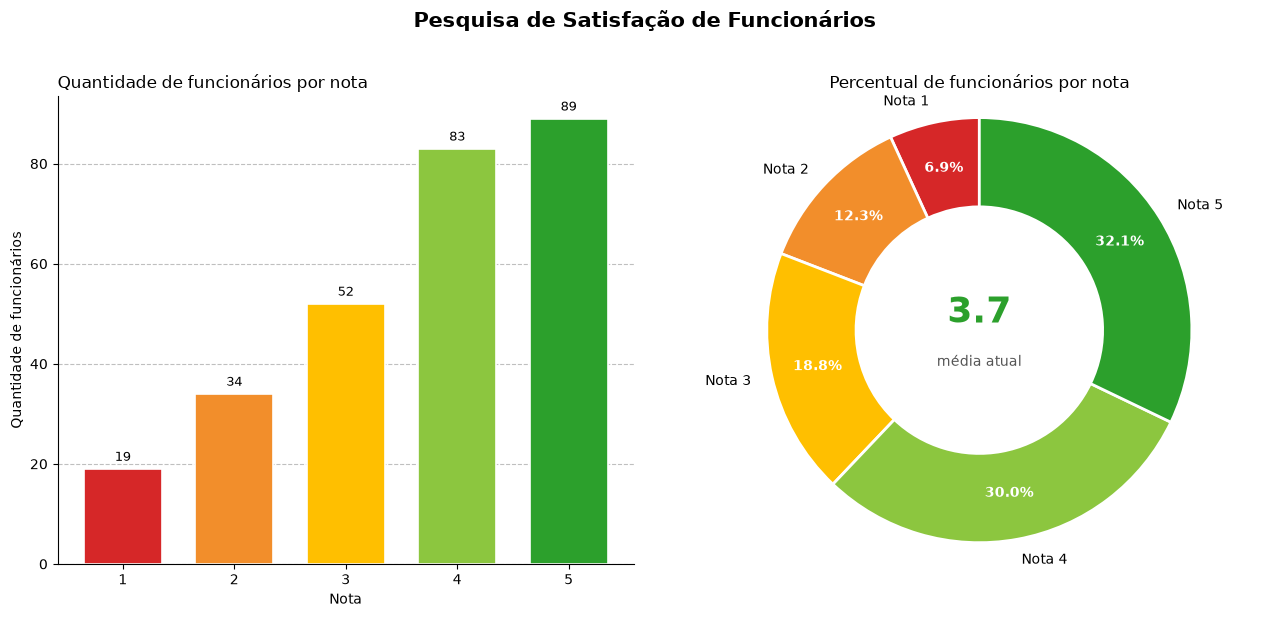

In [45]:
CORES_NOTA = {1: '#d62728', 2: '#f28e2b', 3: '#ffbf00', 4: '#8cc63f', 5: '#2ca02c'}
cores = [CORES_NOTA[int(n)] for n in resumo['Satisfaction']]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))

# ── Gráfico 1: barras ─────────────────────────────────────
bars = ax1.bar(
    resumo['Satisfaction'], resumo['Quantidade'],
    color=cores, edgecolor='white', linewidth=1.2, width=0.7,
)
for bar, qtd in zip(bars, resumo['Quantidade']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{qtd}', ha='center', va='bottom', fontsize=9)

ax1.set_title('Quantidade de funcionários por nota', loc='left')
ax1.set_xlabel('Nota')
ax1.set_ylabel('Quantidade de funcionários')
ax1.set_xticks(resumo['Satisfaction'])
ax1.yaxis.grid(True, linestyle='--', alpha=0.8)
ax1.set_axisbelow(True)
ax1.spines[['top', 'right']].set_visible(False)

# ── Gráfico 2: pizza (donut com KPI central) ─────────────
wedges, texts, autotexts = ax2.pie(
    resumo['Quantidade'],
    labels=[f'Nota {n}' for n in resumo['Satisfaction']],
    colors=cores,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.78,
    wedgeprops=dict(width=0.42, edgecolor='white', linewidth=2),
)
for t in autotexts:
    t.set_color('white')
    t.set_fontweight('bold')

ax2.text(0, 0.08, f'{satisfacao_media:.1f}', ha='center', va='center',
         fontsize=26, fontweight='bold', color='#2ca02c')
ax2.text(0, -0.15, 'média atual', ha='center', va='center',
         fontsize=10, color='#555')
ax2.set_title('Percentual de funcionários por nota', loc='center')
ax2.axis('equal')

# ── Título geral da figura ───────────────────────────────
fig.suptitle('Pesquisa de Satisfação de Funcionários',
             fontsize=15, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('dashboard_satisfacao_funcionarios.png', bbox_inches='tight', dpi=150)

## Conclusão

Foram analisados 277 colaboradores (última resposta de cada e-mail). A distribuição das notas foi:

| Nota | Categoria          | Qtd | %     |
| ---- | ------------------ | --- | ----- |
| 1    | Muito insatisfeito | 19  | 6,9%  |
| 2    | Insatisfeito       | 34  | 12,3% |
| 3    | Neutro             | 52  | 18,8% |
| 4    | Satisfeito         | 83  | 30,0% |
| 5    | Muito satisfeito   | 89  | 32,1% |


Média: 3,7 / 5 · Mediana: 4 · NPS simplificado (promotores − detratores): +13,0

A maioria dos colaboradores (62,1%) se declara satisfeita ou muito satisfeita, enquanto 19,2% se declaram insatisfeitos. O grupo de insatisfeitos (notas 1–2) representa 1 em cada 5 colaboradores e merece atenção.